# Table of Contents
- [11.0 Introduction: real data is messy](#intro)
- [11.1 The Keeling curve: carbon dioxide at Mauna Loa](#co2)
- [11.2 The solar cycle: 275 years of sunspots](#sunspots)
- [11.3 Kepler's third law and the mass of Jupiter](#kepler)
- [11.4 The hydrogen spectrum and the Rydberg constant](#rydberg)
- [11.5 GW150914: the first detection of gravitational waves](#gw)
- [Problems](#problems)

# 11.0 Introduction: real data is messy <a class="anchor" id="intro"></a>
Every dataset in the course so far was *synthetic*: we knew the right answer because we put it there. Real measurements are different. They come in awkward file formats, have gaps and flagged values, are drowned in noise, carry systematic effects nobody warned you about, and the "right answer" is what you're trying to find out.

In this chapter we analyse five real datasets with the tools from Chapters 3-10:

| Dataset | Source | Methods used |
| :--- | :--- | :--- |
| Monthly atmospheric CO$_2$ at Mauna Loa, 1958-today | NOAA Global Monitoring Laboratory | linear least squares (Ch. 6, 9), FFT (Ch. 8), finite differences (Ch. 4), root finding (Ch. 3) |
| Monthly sunspot number, 1749-today | SILSO, Royal Observatory of Belgium | convolution and smoothing, power spectra (Ch. 8), bootstrap (Ch. 9, 10) |
| Planetary and lunar orbits | NASA planetary fact sheets | log-log fitting with uncertainties (Ch. 9) |
| Hydrogen Balmer lines | NIST Atomic Spectra Database | linear least squares (Ch. 6, 9) |
| Gravitational-wave strain from the two LIGO detectors | Gravitational Wave Open Science Center (GWOSC) | spectral estimation, whitening, filtering, cross-correlation, matched filtering (Ch. 8), optimisation (Ch. 3) |

The first two and the last are files in the `data/` folder next to this notebook (downloaded in October 2026 - the CO$_2$ and sunspot records are updated monthly, so you can download newer versions and re-run everything). The small tables in 11.3 and 11.4 are typed in directly, with their sources.

**A workflow for any dataset:**
1. **Look at the raw file** before writing any code. What are the columns, units, comment lines and missing-value flags?
2. **Plot everything.** Your eyes are the best anomaly detector you have.
3. **Model** the data, and quote **uncertainties** on every fitted number.
4. **Look at the residuals.** Whatever your model doesn't explain is where the next piece of physics (or the next bug) is hiding.

In [1]:
# BLOCK 11.0.1
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.optimize import brentq, curve_fit

DATA = 'data/'

# 11.1 The Keeling curve: carbon dioxide at Mauna Loa <a class="anchor" id="co2"></a>
In 1958 Charles David Keeling began measuring $\text{CO}_2$ on the slopes of Mauna Loa in Hawaii, far from local pollution. It is the longest continuous record of atmospheric $\text{CO}_2$ and one of the most important datasets in science.

### Step 1: look at the file
Let's print the first few lines that *aren't* comments (comments start with `#`).

In [2]:
# BLOCK 11.1.1
with open(DATA + 'co2_mm_mlo.csv') as f:
    lines = [line.rstrip() for line in f if not line.startswith('#')]
print(f'{len(lines)} non-comment lines. The first four:')
print('\n'.join(lines[:4]))

823 non-comment lines. The first four:
year,month,decimal date,average,deseasonalized,ndays,sdev,unc
1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99


The first line is a header. The columns we need are `decimal date` (the time in years) and `average` (the monthly mean CO$_2$ mole fraction in parts per million, ppm). The file's comments tell us that missing months have been interpolated and flagged with a negative standard deviation - always read the comments! `np.genfromtxt` reads such files in one line.

822 months from 1958.20 to 2026.62;  CO2 rose from 315.7 to 427.6 ppm
any obviously bad values (< 0)? False


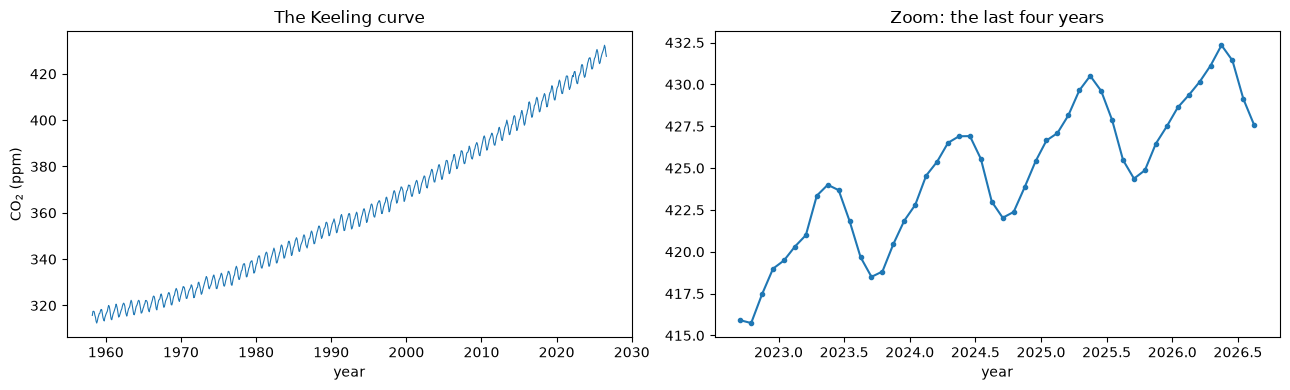

In [3]:
# BLOCK 11.1.2
raw = np.genfromtxt(DATA + 'co2_mm_mlo.csv', delimiter=',', comments='#')
raw = raw[~np.isnan(raw[:, 0])]               # the text header row becomes NaNs - drop it
t_co2, co2 = raw[:, 2], raw[:, 3]
print(f'{len(co2)} months from {t_co2[0]:.2f} to {t_co2[-1]:.2f};  '
      f'CO2 rose from {co2[0]:.1f} to {co2[-1]:.1f} ppm')
print('any obviously bad values (< 0)?', np.any(co2 < 0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(t_co2, co2, lw=0.8)
ax1.set_xlabel('year'); ax1.set_ylabel('CO$_2$ (ppm)'); ax1.set_title('The Keeling curve')
recent = t_co2 > t_co2[-1] - 4
ax2.plot(t_co2[recent], co2[recent], 'o-', ms=3)
ax2.set_xlabel('year'); ax2.set_title('Zoom: the last four years')
plt.tight_layout(); plt.show()

Two things jump out: a steady, *accelerating* rise, and a regular seasonal wiggle. Northern-hemisphere plants absorb CO$_2$ as they grow in spring and summer, and release it as they decay in autumn and winter - we are watching the planet breathe.

### Step 2: a model, fitted by linear least squares
Model the record as a smooth trend plus an annual cycle and its first harmonic (the seasonal shape isn't a pure sine wave):

$$C(t) = a_0 + a_1\tau + a_2\tau^2 + a_3\tau^3 + \sum_{k=1}^{2}\left[b_k\cos(2\pi k t) + c_k\sin(2\pi k t)\right], \qquad \tau = t - 2000.$$

It looks complicated, but it is **linear in all ten parameters**, so it is one call to `np.linalg.lstsq` (Chapter 6.9). We centre time on 2000 to keep the design matrix well-conditioned (Chapter 6.4) - try $\tau=t$ and look at `np.linalg.cond`!

condition number of the design matrix: 3.6e+04
rms residual: 0.77 ppm
peak-to-peak seasonal amplitude: 6.22 ppm


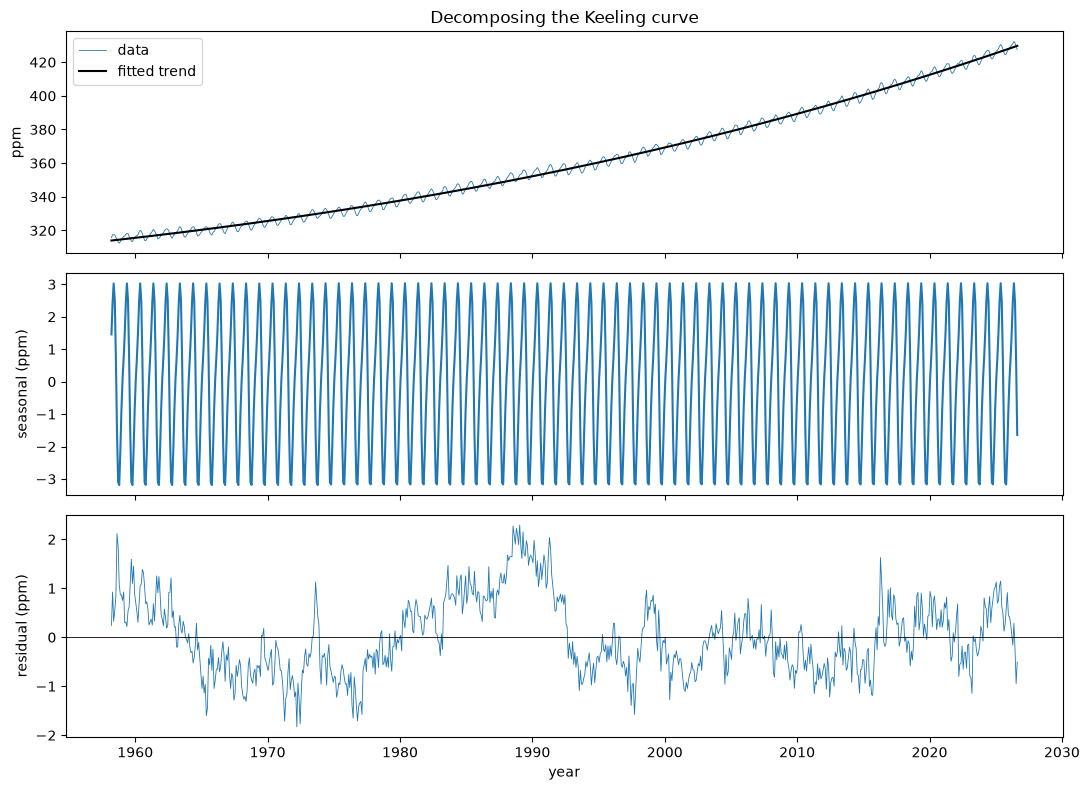

In [4]:
# BLOCK 11.1.3
def design_matrix(t):
    tau = t - 2000
    cols = [np.ones_like(t), tau, tau**2, tau**3]
    for k in (1, 2):
        cols += [np.cos(2*np.pi*k*t), np.sin(2*np.pi*k*t)]
    return np.column_stack(cols)

A = design_matrix(t_co2)
coef, *_ = np.linalg.lstsq(A, co2, rcond=None)
model = A @ coef
resid = co2 - model
trend = A[:, :4] @ coef[:4]
seasonal = A[:, 4:] @ coef[4:]
print(f'condition number of the design matrix: {np.linalg.cond(A):.1e}')
print(f'rms residual: {resid.std():.2f} ppm')
print(f'peak-to-peak seasonal amplitude: {seasonal.max() - seasonal.min():.2f} ppm')

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(t_co2, co2, lw=0.6, label='data'); axes[0].plot(t_co2, trend, 'k', label='fitted trend')
axes[0].set_ylabel('ppm'); axes[0].legend()
axes[1].plot(t_co2, seasonal); axes[1].set_ylabel('seasonal (ppm)')
axes[2].plot(t_co2, resid, lw=0.6); axes[2].axhline(0, color='k', lw=0.6)
axes[2].set_ylabel('residual (ppm)'); axes[2].set_xlabel('year')
axes[0].set_title('Decomposing the Keeling curve')
plt.tight_layout(); plt.show()

The residuals are only about half a ppm, but they are clearly **not** random noise: there are slow wiggles lasting a few years. These are real! Much of this variability is linked to the El Niño-Southern Oscillation, which changes how much carbon tropical forests and oceans take up. This is what "look at the residuals" means in practice.

Is the seasonal cycle growing? Fit the seasonal amplitude separately in each decade (a "rolling" fit) - an easy extension using the same design matrix.

In [5]:
# BLOCK 11.1.4
print(' decade      seasonal peak-to-peak (ppm)')
for start in range(1960, 2030, 10):
    m = (t_co2 >= start) & (t_co2 < start + 10)
    if m.sum() < 60:
        continue
    c, *_ = np.linalg.lstsq(design_matrix(t_co2[m]), co2[m], rcond=None)
    tt = np.linspace(start, start + 1, 400)
    s = design_matrix(tt)[:, 4:] @ c[4:]
    print(f' {start}s      {s.max() - s.min():.2f}')

 decade      seasonal peak-to-peak (ppm)
 1960s      5.91
 1970s      6.02
 1980s      6.44
 1990s      6.62
 2000s      6.43
 2010s      6.84
 2020s      6.55


The amplitude has grown by roughly 10-15% since the 1960s - a sign of a more vigorous northern biosphere.

### Step 3: the growth rate, by numerical differentiation
How fast is CO$_2$ rising, and is it speeding up? Differentiating noisy monthly data directly amplifies the noise (Chapter 4.1), so we first remove the seasonal cycle and smooth with a 12-month running mean - a **convolution** (Chapter 8.7) - and then take a central difference with `np.gradient`.

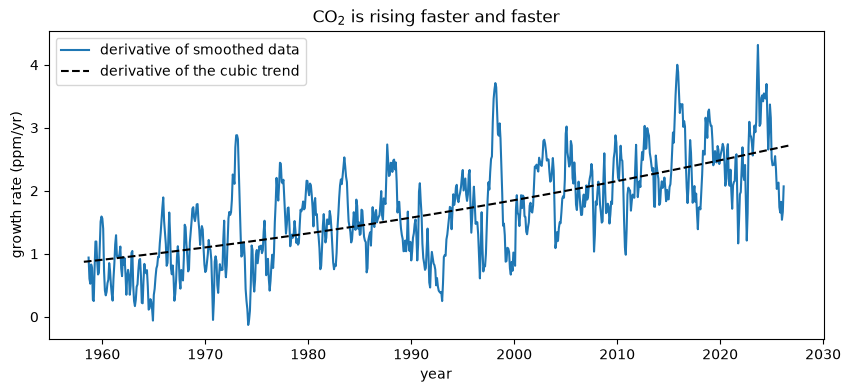

average growth rate in the decade from 1965: 1.10 ppm/yr
average growth rate in the decade from 1990: 1.51 ppm/yr
average growth rate in the decade from 2015: 2.64 ppm/yr


In [6]:
# BLOCK 11.1.5
deseason = co2 - seasonal
kernel = np.ones(12)/12
smooth = np.convolve(deseason, kernel, mode='valid')          # 'valid' drops the ends where the kernel overhangs
t_smooth = np.convolve(t_co2, kernel, mode='valid')
rate = np.gradient(smooth, t_smooth)                          # ppm per year

plt.figure(figsize=(10, 4))
plt.plot(t_smooth, rate, label='derivative of smoothed data')
plt.plot(t_co2, np.gradient(trend, t_co2), 'k--', label='derivative of the cubic trend')
plt.xlabel('year'); plt.ylabel('growth rate (ppm/yr)'); plt.legend()
plt.title('CO$_2$ is rising faster and faster'); plt.show()
for y in (1965, 1990, 2015):
    print(f'average growth rate in the decade from {y}: {rate[(t_smooth >= y) & (t_smooth < y + 10)].mean():.2f} ppm/yr')

### Step 4: a spectral check
We *assumed* the seasonal cycle has a period of exactly one year. Let's let the data speak: subtract the trend, take the FFT of the evenly-sampled monthly series, and look at the power spectrum (Chapter 8.3). The sample spacing is 1/12 yr, so frequencies come out in cycles per year.

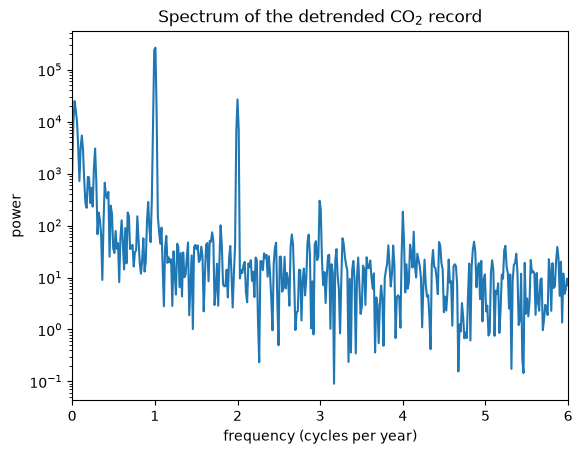

strongest spectral peaks at [1.007 2.    0.029] cycles per year


In [7]:
# BLOCK 11.1.6
detrended = co2 - trend
P = np.abs(np.fft.rfft(detrended*np.hanning(detrended.size)))**2
nu = np.fft.rfftfreq(detrended.size, d=1/12)
plt.semilogy(nu, P)
plt.xlabel('frequency (cycles per year)'); plt.ylabel('power'); plt.xlim(0, 6)
plt.title('Spectrum of the detrended CO$_2$ record'); plt.show()
peaks, _ = signal.find_peaks(P, prominence=P.max()/100)
print('strongest spectral peaks at', np.round(nu[peaks][np.argsort(P[peaks])[::-1][:3]], 3), 'cycles per year')

Peaks at 1 and 2 cycles per year confirm the model. The rising power at very low frequency is the slow, multi-year variability we saw in the residuals.

### Step 5: a (cautious) extrapolation
When does the fitted trend cross 450 ppm? That's a root-finding problem (Chapter 3). But remember: extrapolating a polynomial beyond the data is dangerous - the answer depends entirely on whether future emissions follow the past pattern, which is a question about human behaviour, not physics.

In [8]:
# BLOCK 11.1.7
trend_func = lambda t: (design_matrix(np.atleast_1d(t))[:, :4] @ coef[:4])[0]
t450 = brentq(lambda t: trend_func(t) - 450, t_co2[-1] - 5, t_co2[-1] + 40)
print(f'the cubic trend reaches 450 ppm in {t450:.1f}')
print(f'pre-industrial CO2 was about 280 ppm; the latest monthly value is {co2[-1]:.1f} ppm '
      f'({co2[-1]/280 - 1:.0%} higher)')

the cubic trend reaches 450 ppm in 2033.8
pre-industrial CO2 was about 280 ppm; the latest monthly value is 427.6 ppm (53% higher)


# 11.2 The solar cycle: 275 years of sunspots <a class="anchor" id="sunspots"></a>
Astronomers have counted sunspots since Galileo. The SILSO file gives the monthly mean **total sunspot number** since 1749. The columns are: year; month; decimal date; sunspot number; standard deviation; number of observations; a definitive/provisional flag. They are separated by semicolons, and missing values are marked $-1$.

In [9]:
# BLOCK 11.2.1
ss = np.genfromtxt(DATA + 'SN_m_tot_V2.0.csv', delimiter=';')
t_ss, sn = ss[:, 2], ss[:, 3]
print(f'{len(sn)} months, {t_ss[0]:.1f} to {t_ss[-1]:.1f};  missing values: {np.sum(sn < 0)}')

3333 months, 1749.0 to 2026.7;  missing values: 0


**Smoothing.** The monthly values are very noisy. The standard way to show the solar cycle is the **13-month smoothed** sunspot number: a centred running mean over 13 months with half weights on the two end months, so that the window spans exactly one year. That's a convolution with the kernel $\frac{1}{24}[1, 2, 2, \dots, 2, 1]$.

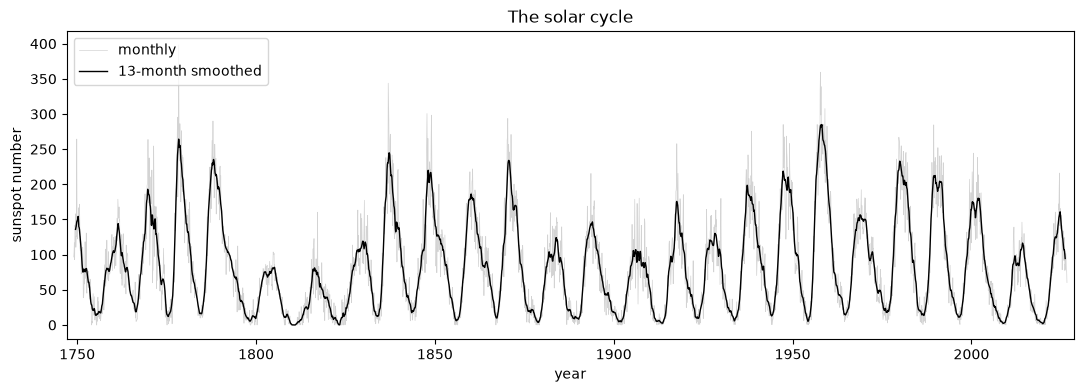

In [10]:
# BLOCK 11.2.2
kernel13 = np.r_[1, 2*np.ones(11), 1]/24
sn_smooth = np.convolve(sn, kernel13, mode='same')
sn_smooth[:6] = sn_smooth[-6:] = np.nan                        # the ends aren't fully covered by the kernel

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t_ss, sn, color='lightgrey', lw=0.5, label='monthly')
ax.plot(t_ss, sn_smooth, 'k', lw=1, label='13-month smoothed')
ax.set_xlabel('year'); ax.set_ylabel('sunspot number'); ax.legend(loc='upper left')
ax.set_xlim(t_ss[0] - 2, t_ss[-1] + 2)
ax.set_title('The solar cycle'); plt.show()

### The period from the power spectrum
The monthly record is evenly sampled, so we can compute a power spectrum directly (subtracting the mean first, so the huge zero-frequency term doesn't dominate). To read off a period, plot against $1/\nu$.

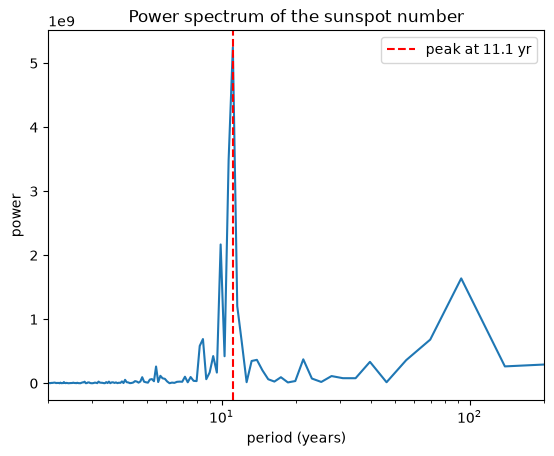

In [11]:
# BLOCK 11.2.3
x = sn - sn.mean()
P = np.abs(np.fft.rfft(x))**2
nu = np.fft.rfftfreq(x.size, d=1/12)                          # cycles per year
period = 1/nu[1:]
plt.semilogx(period, P[1:])
plt.xlabel('period (years)'); plt.ylabel('power'); plt.xlim(2, 200)
best = period[np.argmax(P[1:])]
plt.axvline(best, color='r', ls='--', label=f'peak at {best:.1f} yr')
plt.legend(); plt.title('Power spectrum of the sunspot number'); plt.show()

A strong peak near 11 years (the **Schwabe cycle**). The peak is broad because the cycle length genuinely varies, and the frequency resolution $1/T\approx 1/275$ yr$^{-1}$ is coarse at long periods. There is also power at around 100 years (the **Gleissberg cycle**) - look at the envelope of the maxima in the previous plot.

### Cycle by cycle: finding minima
A more direct approach: find every **minimum** of the smoothed curve and measure the time between them. `scipy.signal.find_peaks` finds local maxima; applying it to $-S(t)$ finds minima. We tell it that minima are at least 7 years apart, to avoid being fooled by small wiggles.

In [12]:
# BLOCK 11.2.4
valid = ~np.isnan(sn_smooth)
ts, ys = t_ss[valid], sn_smooth[valid]
minima, _ = signal.find_peaks(-ys, distance=7*12)
maxima, _ = signal.find_peaks(ys, distance=7*12)
t_min = ts[minima]
lengths = np.diff(t_min)
print('years of solar minimum:', np.round(t_min, 1))
print(f'{len(lengths)} complete cycles: mean length {lengths.mean():.2f} yr, '
      f'standard deviation {lengths.std(ddof=1):.2f} yr, range {lengths.min():.1f}-{lengths.max():.1f} yr')

years of solar minimum: [1755.1 1766.5 1775.5 1784.7 1798.3 1810.6 1823.4 1833.9 1843.5 1856.
 1867.2 1879.  1890.2 1902.  1913.5 1923.6 1933.7 1944.1 1954.3 1964.8
 1976.2 1986.7 1996.4 2009.  2020. ]
24 complete cycles: mean length 11.03 yr, standard deviation 1.18 yr, range 9.0-13.6 yr


How precisely do we know the *mean* cycle length? With only ~25 cycles, we use the **bootstrap** (Chapter 9.7): resample the cycle lengths with replacement many times and look at the spread of the means.

In [13]:
# BLOCK 11.2.5
rng = np.random.default_rng(1)
boot = np.array([rng.choice(lengths, lengths.size).mean() for _ in range(10000)])
print(f'mean cycle length = {lengths.mean():.2f} ± {boot.std():.2f} yr  (bootstrap)')
print(f'compare the standard error formula sigma/sqrt(n) = {lengths.std(ddof=1)/np.sqrt(lengths.size):.2f} yr')

mean cycle length = 11.03 ± 0.23 yr  (bootstrap)
compare the standard error formula sigma/sqrt(n) = 0.24 yr


### The Waldmeier effect
In 1935 Max Waldmeier noticed that **strong cycles rise faster**. To test this we need, for each cycle, its peak height and its *rise time* (from the starting minimum to the maximum). We pair them carefully: each cycle's maximum is the largest smoothed value *between* its two minima. Then we measure the correlation coefficient $r$, and use the bootstrap again - this time resampling (rise time, peak) *pairs* - to get a confidence interval on $r$.

correlation between rise time and peak height: r = -0.74, 95% bootstrap interval [-0.87, -0.56]


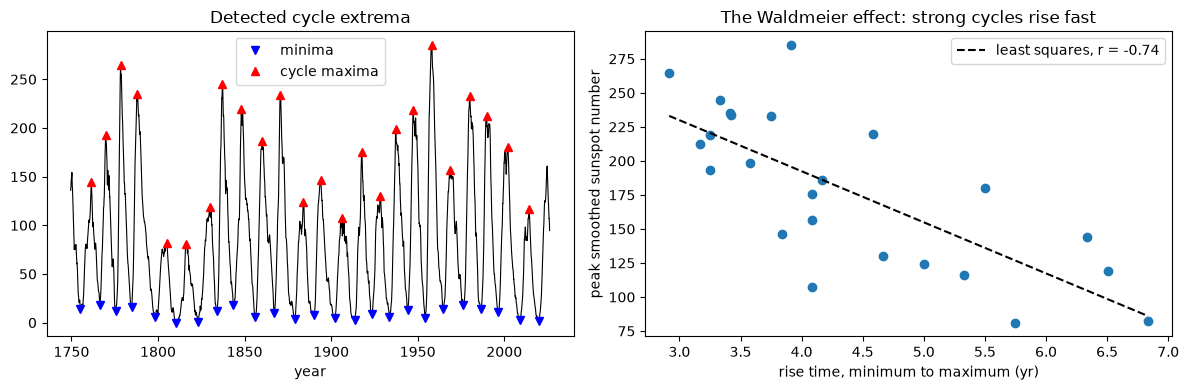

In [14]:
# BLOCK 11.2.6
peak_idx = np.array([minima[i] + np.argmax(ys[minima[i]:minima[i+1]]) for i in range(len(minima) - 1)])
peaks_h = ys[peak_idx]
rise = ts[peak_idx] - t_min[:-1]

r = np.corrcoef(rise, peaks_h)[0, 1]
r_boot = []
for _ in range(10000):
    k = rng.integers(0, rise.size, rise.size)
    r_boot.append(np.corrcoef(rise[k], peaks_h[k])[0, 1])
lo, hi = np.percentile(r_boot, [2.5, 97.5])
print(f'correlation between rise time and peak height: r = {r:.2f}, 95% bootstrap interval [{lo:.2f}, {hi:.2f}]')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(ts, ys, 'k', lw=0.8)
ax1.plot(ts[minima], ys[minima], 'bv', label='minima'); ax1.plot(ts[peak_idx], peaks_h, 'r^', label='cycle maxima')
ax1.set_xlabel('year'); ax1.legend(); ax1.set_title('Detected cycle extrema')
ax2.plot(rise, peaks_h, 'o')
slope_w, icpt_w = np.polyfit(rise, peaks_h, 1)
rr = np.linspace(rise.min(), rise.max(), 10)
ax2.plot(rr, icpt_w + slope_w*rr, 'k--', label=f'least squares, r = {r:.2f}')
ax2.set_xlabel('rise time, minimum to maximum (yr)'); ax2.set_ylabel('peak smoothed sunspot number')
ax2.legend(); ax2.set_title('The Waldmeier effect: strong cycles rise fast')
plt.tight_layout(); plt.show()

The bootstrap interval lies entirely below zero, so the anti-correlation is unlikely to be a fluke of our small sample of ~24 cycles. Effects like this are used to forecast a cycle's strength once it has started rising.

# 11.3 Kepler's third law and the mass of Jupiter <a class="anchor" id="kepler"></a>
Kepler's third law, $T^2 = \frac{4\pi^2}{GM}a^3$, says that $\log T$ against $\log a$ is a straight line of slope $3/2$. Let's test it with the eight planets. The semi-major axes $a$ (in AU) are from JPL's table of planetary orbital elements (Standish), and the sidereal orbital periods $T$ (in Julian years of 365.25 days) are from the same source.

slope = 1.49986 ± 0.00003   (Kepler: 3/2)
mass of the Sun: 1.9894e+30 kg (scatter between planets 5e-04);  accepted 1.9885e30 kg


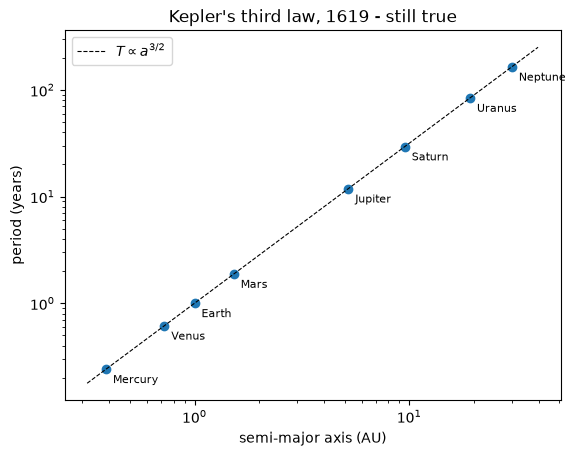

In [15]:
# BLOCK 11.3.1
planets = ['Mercury', 'Venus', 'Earth', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune']
a_pl = np.array([0.38709927, 0.72333566, 1.00000261, 1.52371034, 5.20288700, 9.53667594, 19.18916464, 30.06992276])
T_pl = np.array([0.2408467, 0.61519726, 1.0000174, 1.8808476, 11.862615, 29.447498, 84.016846, 164.79132])

# 1) Test the power law: a straight-line fit in log space, with uncertainties from the covariance matrix
(slope, intercept), cov = np.polyfit(np.log10(a_pl), np.log10(T_pl), 1, cov=True)
print(f'slope = {slope:.5f} ± {np.sqrt(cov[0, 0]):.5f}   (Kepler: 3/2)')

# 2) Now *assume* the slope is 3/2 and use every planet to measure GM_sun: T^2 = 4 pi^2 a^3 / GM
G, AU, yr = 6.674e-11, 1.495978707e11, 365.25*86400
GM_each = 4*np.pi**2*(a_pl*AU)**3/(T_pl*yr)**2
M_sun = GM_each.mean()/G
print(f'mass of the Sun: {M_sun:.4e} kg (scatter between planets {GM_each.std()/GM_each.mean():.0e});  accepted 1.9885e30 kg')

plt.loglog(a_pl, T_pl, 'o')
aa = np.logspace(-0.5, 1.6, 50)
plt.loglog(aa, aa**1.5, 'k--', lw=0.8, label=r'$T \propto a^{3/2}$')
for name, a, T in zip(planets, a_pl, T_pl):
    plt.annotate(name, (a, T), textcoords='offset points', xytext=(5, -10), fontsize=8)
plt.xlabel('semi-major axis (AU)'); plt.ylabel('period (years)'); plt.legend()
plt.title("Kepler's third law, 1619 - still true"); plt.show()

Why fix the slope before measuring the mass? If we used the intercept of the *free* fit, any tiny error in the slope would be multiplied by $\log a$ and leak into the intercept. When theory tells you a parameter exactly, fix it - you get a much better measurement of the rest. (The planets' own masses make the slope deviate from 3/2 very slightly - Jupiter's period depends on $G(M_\odot + M_J)$, which is 0.1% bigger.)

The same law applied to the four **Galilean moons** weighs Jupiter. Here we fit the single parameter $GM_J$ with `curve_fit` on $T(a) = 2\pi\sqrt{a^3/GM_J}$. We assume the semi-major axes are uncertain by 1 part in $10^4$, which (since $T\propto a^{3/2}$) means an uncertainty of $1.5\times10^{-4}$ in each predicted period.

In [16]:
# BLOCK 11.3.2
moons = ['Io', 'Europa', 'Ganymede', 'Callisto']
a_m = np.array([421700, 671034, 1070412, 1882709])*1e3             # m
T_m = np.array([1.769137786, 3.551181, 7.15455296, 16.6890184])*86400.0   # s
kepler = lambda a, GM: 2*np.pi*np.sqrt(a**3/GM)
(GM_J,), cov = curve_fit(kepler, a_m, T_m, p0=[1e17], sigma=1.5e-4*T_m, absolute_sigma=True)
M_J, dM_J = GM_J/G, np.sqrt(cov[0, 0])/G
print(f'M_Jupiter = ({M_J/1e27:.4f} ± {dM_J/1e27:.4f}) x 10^27 kg   (accepted 1.8982 x 10^27 kg)')
print(f'M_Sun / M_Jupiter = {M_sun/M_J:.0f}  (accepted 1047.6)')

M_Jupiter = (1.8986 ± 0.0003) x 10^27 kg   (accepted 1.8982 x 10^27 kg)
M_Sun / M_Jupiter = 1048  (accepted 1047.6)


Since $G$ itself is only known to about 22 parts per million, astronomers usually quote $GM$, which is measured far more precisely than either factor.

# 11.4 The hydrogen spectrum and the Rydberg constant <a class="anchor" id="rydberg"></a>
The visible lines of hydrogen (the **Balmer series**) come from transitions down to the $n=2$ level. Bohr's model predicts

$$\frac{1}{\lambda_\text{vac}} = R_H\left(\frac{1}{2^2} - \frac{1}{n^2}\right),\quad n = 3, 4, 5, \dots$$

so plotting $1/\lambda$ against $1/n^2$ should give a straight line with slope $-R_H$ and intercept $R_H/4$. Below are the wavelengths of the first seven lines **measured in air**, as tabulated in the NIST Atomic Spectra Database.

**A real-world subtlety:** spectroscopists quote wavelengths in *air* above 200 nm, but Bohr's formula is for *vacuum*. Light travels slower in air ($n_\text{air}\approx1.00028$), so $\lambda_\text{vac} = n_\text{air}\lambda_\text{air}$. Ignoring this shifts $R_H$ by 3 parts in $10^4$ - far bigger than the measurement errors. We use Edlén's empirical formula for the refractive index of standard air. In it, $s = 1/\lambda_\text{vac}$ measured in $\mu\text{m}^{-1}$ (we can safely use $\lambda_\text{air}$ instead when computing $s$, because the difference is tiny):

$$n_\text{air} - 1 = 10^{-8}\left(8342.54 + \frac{2406147}{130 - s^2} + \frac{15998}{38.9 - s^2}\right).$$

air (wrong!) : R_H from slope = 1.097099e+07 m^-1, from intercept = 1.097095e+07 m^-1
vacuum       : R_H from slope = 1.096776e+07 m^-1, from intercept = 1.096784e+07 m^-1
theory      : R_H = R_inf / (1 + m_e/m_p) = 1.096776e+07 m^-1


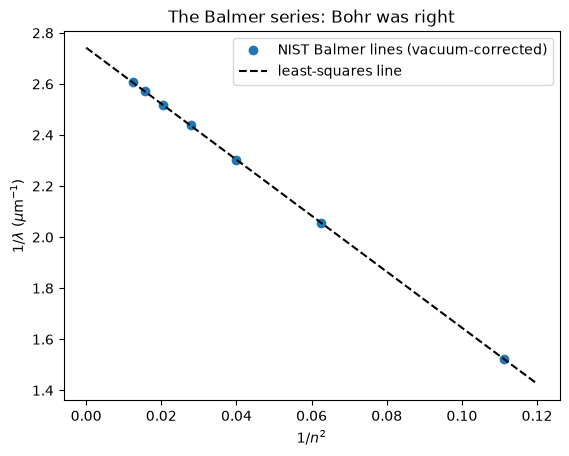

In [17]:
# BLOCK 11.4.1
n_upper = np.arange(3, 10)
lam_air = np.array([656.279, 486.135, 434.0472, 410.1734, 397.0075, 388.9064, 383.5397])*1e-9   # m

s2 = (1e-6/lam_air)**2
n_air = 1 + 1e-8*(8342.54 + 2406147/(130 - s2) + 15998/(38.9 - s2))
lam_vac = n_air*lam_air

x = 1/n_upper**2
for label, lam in [('air (wrong!)', lam_air), ('vacuum', lam_vac)]:
    A = np.column_stack([np.ones_like(x), x])
    (c0, c1), res, *_ = np.linalg.lstsq(A, 1/lam, rcond=None)
    print(f'{label:<13}: R_H from slope = {-c1:.6e} m^-1, from intercept = {4*c0:.6e} m^-1')

R_inf, me_mp = 10973731.568, 1/1836.15267
print(f'theory      : R_H = R_inf / (1 + m_e/m_p) = {R_inf/(1 + me_mp):.6e} m^-1')

A = np.column_stack([np.ones_like(x), x])
(c0, c1), *_ = np.linalg.lstsq(A, 1/lam_vac, rcond=None)
plt.plot(x, 1/lam_vac*1e-6, 'o', label='NIST Balmer lines (vacuum-corrected)')
xx = np.linspace(0, 0.12, 10)
plt.plot(xx, (c0 + c1*xx)*1e-6, 'k--', label='least-squares line')
plt.xlabel('$1/n^2$'); plt.ylabel(r'$1/\lambda$ ($\mu$m$^{-1}$)'); plt.legend()
plt.title('The Balmer series: Bohr was right'); plt.show()

Notice the theoretical value uses the **reduced mass**: the electron and proton both orbit their common centre of mass, so hydrogen's Rydberg constant is slightly smaller than $R_\infty$. With the air correction, our fit agrees with theory to a few parts in $10^6$ - and is sensitive enough to *see* the reduced-mass correction (5 parts in $10^4$). Without the correction we would get it wrong by more than that. Small systematic effects matter!

# 11.5 GW150914: the first detection of gravitational waves <a class="anchor" id="gw"></a>
On 14 September 2015 the two LIGO detectors, in Hanford (Washington) and Livingston (Louisiana), recorded ripples in spacetime from two black holes, each about 30 times the mass of the Sun, merging 1.3 billion light years away. The strain - the fractional change in length of the 4 km detector arms - was about $10^{-21}$: a thousandth of the width of a proton.

The files contain 32 seconds of strain sampled at 4096 Hz from each detector, released by the Gravitational Wave Open Science Center. We'll follow the steps of the real analysis: estimate the noise, whiten, filter, compare detectors, and finally **matched-filter** with a theoretical chirp to estimate the black holes' mass.

H1: 131072 samples, rms strain = 2.20e-19
L1: 131072 samples, rms strain = 2.34e-19


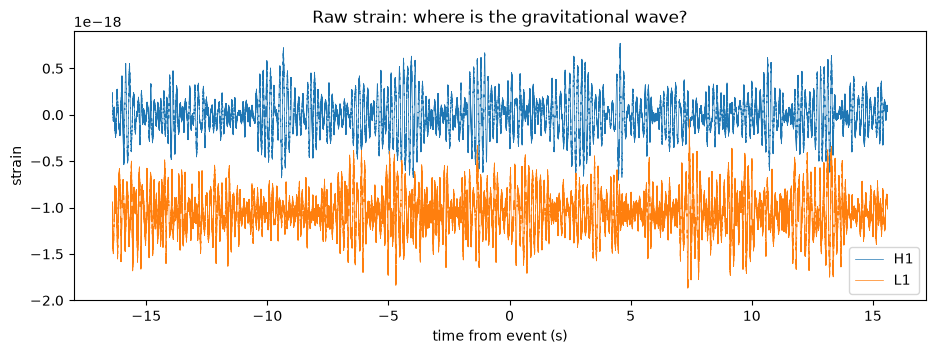

In [18]:
# BLOCK 11.5.1
fs = 4096
gps_start = 1126259446
t_event = 1126259462.4 - gps_start                       # approximate event time in our files (s)
strain = {det: np.loadtxt(DATA + f'{det[0]}-{det}_LOSC_4_V2-1126259446-32.txt.gz') for det in ['H1', 'L1']}
t = np.arange(strain['H1'].size)/fs
for det, h in strain.items():
    print(f'{det}: {h.size} samples, rms strain = {h.std():.2e}')

plt.figure(figsize=(11, 3.5))
for det, h in strain.items():
    plt.plot(t - t_event, h, lw=0.5, label=det)
plt.xlabel('time from event (s)'); plt.ylabel('strain'); plt.legend()
plt.title('Raw strain: where is the gravitational wave?'); plt.show()

Nothing visible! The raw strain is dominated by enormous low-frequency noise (seismic motion), which is about 1000 times larger than the signal.

### Step 1: the noise spectrum
We estimate the **amplitude spectral density** (ASD) - the noise level at each frequency - with **Welch's method**: chop the data into overlapping 4-second segments, window each one (Chapter 8.5), FFT, and average the power spectra. Averaging makes the estimate far less noisy than a single FFT of the whole series.

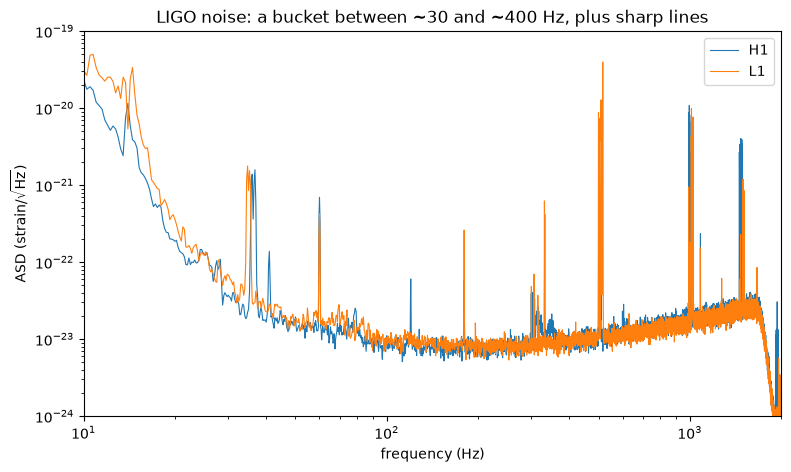

In [19]:
# BLOCK 11.5.2
psd = {}
plt.figure(figsize=(9, 5))
for det, h in strain.items():
    f_w, P = signal.welch(h, fs, nperseg=4*fs)
    psd[det] = (f_w, P)
    plt.loglog(f_w, np.sqrt(P), lw=0.8, label=det)
plt.xlim(10, 2000); plt.ylim(1e-24, 1e-19)
plt.xlabel('frequency (Hz)'); plt.ylabel(r'ASD (strain/$\sqrt{\mathrm{Hz}}$)'); plt.legend()
plt.title('LIGO noise: a bucket between ~30 and ~400 Hz, plus sharp lines'); plt.show()

The detectors are most sensitive between about 30 and 400 Hz. The sharp spikes are instrumental lines: 60 Hz mains power and its harmonics, and the "violin modes" of the mirror suspensions near 500 Hz.

### Step 2: whitening and band-pass filtering
**Whitening** divides the Fourier transform of the data by the ASD, so every frequency carries equal noise power. Loud noisy frequencies are suppressed and quiet ones are boosted. Then a **band-pass** filter keeps only 35-350 Hz. We use a Butterworth filter applied forwards *and* backwards (`filtfilt`) so the result has no phase shift.

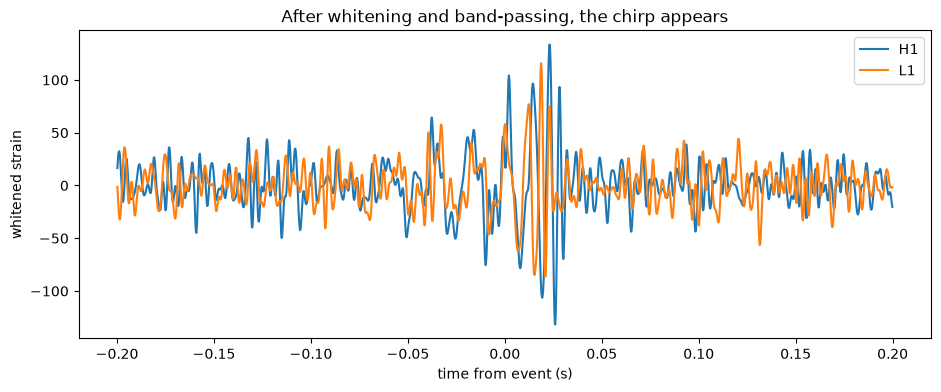

In [20]:
# BLOCK 11.5.3
def whiten(h, f_psd, P):
    window = signal.windows.tukey(h.size, alpha=0.1)       # taper the ends to avoid edge effects
    H = np.fft.rfft(h*window)
    f = np.fft.rfftfreq(h.size, 1/fs)
    return np.fft.irfft(H/np.sqrt(np.interp(f, f_psd, P)), n=h.size)

b, a = signal.butter(4, [35, 350], btype='bandpass', fs=fs)
clean = {det: signal.filtfilt(b, a, whiten(h, *psd[det])) for det, h in strain.items()}

near = np.abs(t - t_event) < 0.2
plt.figure(figsize=(11, 4))
for det in clean:
    plt.plot(t[near] - t_event, clean[det][near], label=det)
plt.xlabel('time from event (s)'); plt.ylabel('whitened strain'); plt.legend()
plt.title('After whitening and band-passing, the chirp appears'); plt.show()

### Step 3: the time delay between the detectors
The two sites are 3000 km apart, so a gravitational wave travelling at the speed of light can arrive at most 10 ms earlier at one than the other. We find the delay by **cross-correlating** the two signals: shift L1 by $k$ samples, multiply by H1 and sum, and find the shift giving the largest $|\text{correlation}|$. The detectors' arms are oriented differently, so we expect the signals to have *opposite signs*.

L1 must be shifted by 7.32 ms to match H1; correlation coefficient = -0.73
light travel time between the sites: 10.0 ms


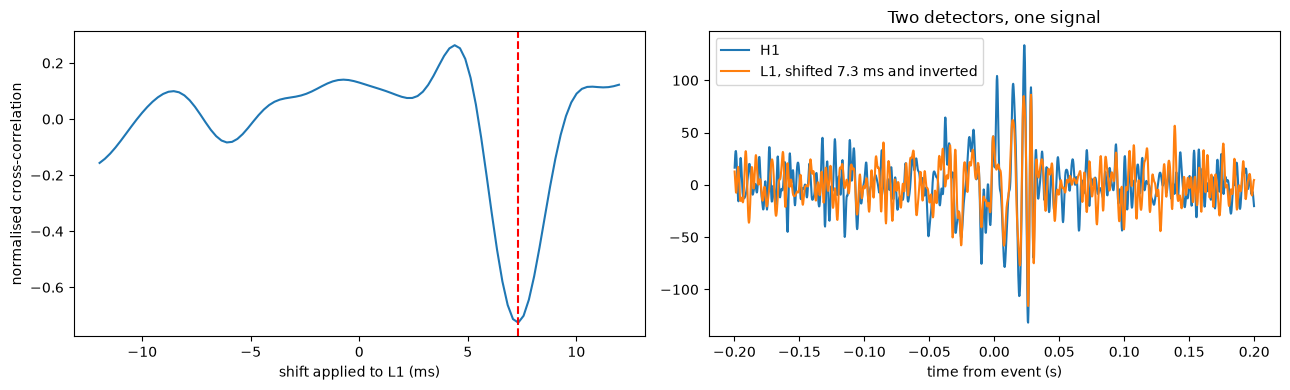

In [21]:
# BLOCK 11.5.4
seg = (t > t_event - 0.15) & (t < t_event + 0.05)
lags = np.arange(-int(0.012*fs), int(0.012*fs) + 1)                   # +/- 12 ms
cc = np.array([np.sum(clean['H1'][seg]*np.roll(clean['L1'], k)[seg]) for k in lags])
cc /= np.sqrt(np.sum(clean['H1'][seg]**2)*np.sum(clean['L1'][seg]**2))
k_best = lags[np.argmax(np.abs(cc))]
print(f'L1 must be shifted by {k_best/fs*1e3:.2f} ms to match H1; correlation coefficient = {cc[np.argmax(np.abs(cc))]:+.2f}')
print(f'light travel time between the sites: {3002e3/2.998e8*1e3:.1f} ms')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(lags/fs*1e3, cc); ax1.axvline(k_best/fs*1e3, color='r', ls='--')
ax1.set_xlabel('shift applied to L1 (ms)'); ax1.set_ylabel('normalised cross-correlation')
ax2.plot(t[near] - t_event, clean['H1'][near], label='H1')
ax2.plot(t[near] - t_event, -np.roll(clean['L1'], k_best)[near], label=f'L1, shifted {k_best/fs*1e3:.1f} ms and inverted')
ax2.set_xlabel('time from event (s)'); ax2.legend(); ax2.set_title('Two detectors, one signal')
plt.tight_layout(); plt.show()

The published delay is $6.9^{+0.5}_{-0.4}$ ms with Livingston first, and we've reproduced it from scratch. A delay this close to the maximum means the source lay roughly along the line joining the detectors, which is why the first sky map was a long, thin arc in the southern sky.

### Step 4: a time-frequency picture
A **spectrogram** - short FFTs on short sliding windows (Chapter 8) - shows how the frequency changes with time. The signal is a **chirp**: as the black holes spiral together, the orbital frequency and the amplitude both rise until they merge.

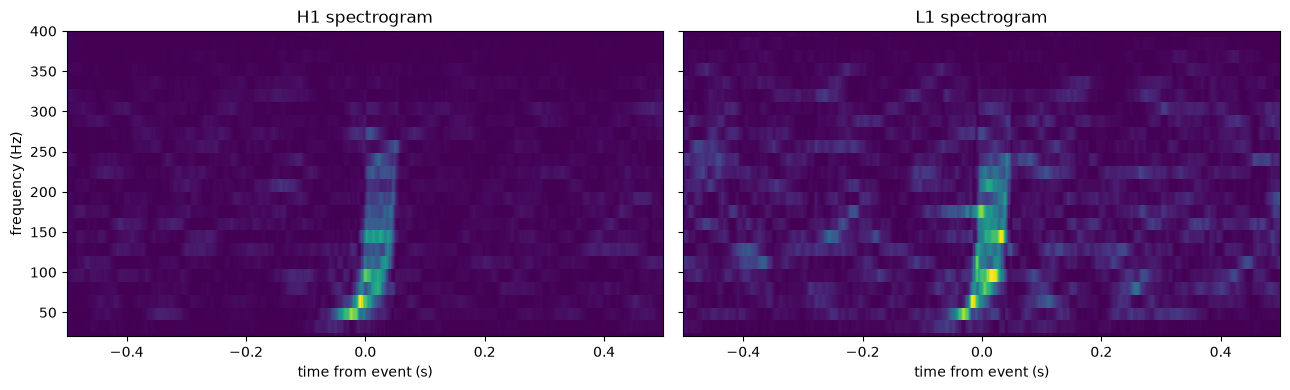

In [22]:
# BLOCK 11.5.5
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, det in zip(axes, clean):
    f_s, t_s, Sxx = signal.spectrogram(clean[det], fs, nperseg=256, noverlap=248)
    w = np.abs(t_s - t_event) < 0.5
    ax.pcolormesh(t_s[w] - t_event, f_s, Sxx[:, w], shading='auto', cmap='viridis')
    ax.set_ylim(20, 400); ax.set_xlabel('time from event (s)'); ax.set_title(f'{det} spectrogram')
axes[0].set_ylabel('frequency (Hz)')
plt.tight_layout(); plt.show()

### Step 5: matched filtering and the chirp mass
Our eyes can find this signal only because it is exceptionally loud. LIGO's searches use **matched filtering**: correlate the data with a theoretical waveform (a *template*), weighting each frequency by how quiet the detector is there. If $\tilde d(f)$ is the data's Fourier transform, $\tilde h(f)$ the template's and $S(f)$ the noise power spectral density, the signal-to-noise ratio as a function of arrival time $t_0$ is

$$\rho(t_0) = \frac{|z(t_0)|}{\sigma}, \qquad z(t_0) = 4\int_{f_\text{low}}^{f_\text{high}}\frac{\tilde d(f)\tilde h^*(f)}{S(f)}e^{2\pi i f t_0}\,df, \qquad \sigma^2 = 4\int\frac{|\tilde h(f)|^2}{S(f)}df.$$

Thanks to the convolution theorem, one inverse FFT computes $z(t_0)$ for **every** arrival time at once.

For the inspiral, general relativity predicts (to lowest order) a template that depends mainly on one combination of the two masses, the **chirp mass** $\mathcal M = \frac{(m_1m_2)^{3/5}}{(m_1+m_2)^{1/5}}$:

$$\tilde h(f)\propto f^{-7/6}\exp\left[-i\left(\frac{3}{128}\left(\frac{\pi G\mathcal M f}{c^3}\right)^{-5/3} - \frac{\pi}{4}\right)\right].$$

We compute $\rho$ for a grid of chirp masses and find the one that fits best: an **optimisation** problem over a template bank.

H1: best chirp mass 36.5 M_sun with SNR 17.0


L1: best chirp mass 34.0 M_sun with SNR 11.9
network SNR 20.6 at chirp mass 36.0 M_sun


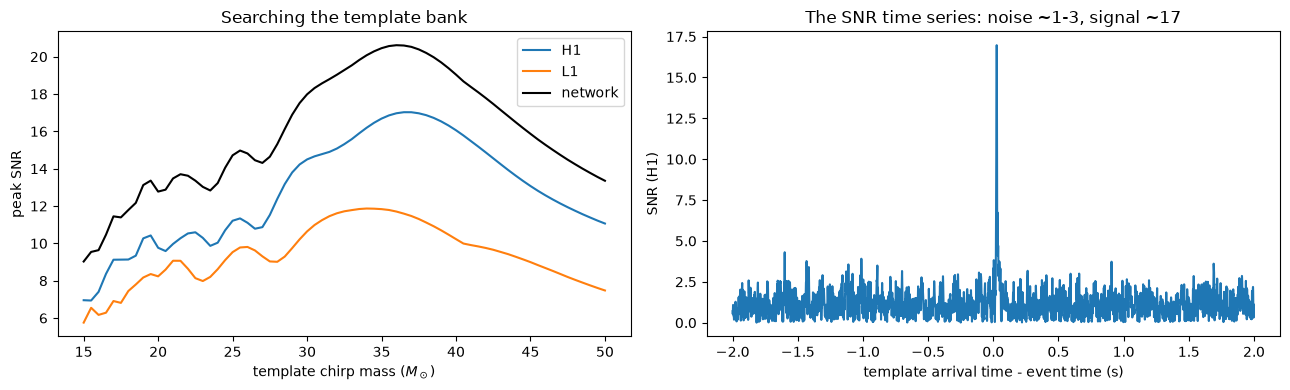

In [23]:
# BLOCK 11.5.6
G, c, M_sun_kg = 6.674e-11, 2.998e8, 1.989e30

def matched_filter_snr(h, f_psd, P, Mc, f_low=30, f_high=400):
    N = h.size
    df = fs/N
    D = np.fft.rfft(h*signal.windows.tukey(N, 0.1))/fs                # approximates the continuous FT
    f = np.fft.rfftfreq(N, 1/fs)
    S = np.interp(f, f_psd, P)
    band = (f > f_low) & (f < f_high)
    H = np.zeros(f.size, complex)
    tau = G*Mc*M_sun_kg/c**3
    H[band] = f[band]**(-7/6)*np.exp(-1j*(3/128*(np.pi*tau*f[band])**(-5/3) - np.pi/4))
    sigma = np.sqrt(4*np.sum(np.abs(H)**2/S)*df)
    integrand = np.concatenate([D*np.conj(H)/S, np.zeros(N - f.size)])  # positive frequencies only -> complex z
    z = 4*np.fft.ifft(integrand)*N*df
    return np.abs(z)/sigma

masses = np.linspace(15, 50, 71)
search = (t > 10) & (t < 22)                                         # avoid the filter's edge effects
results = {}
for det, h in strain.items():
    peak = np.array([matched_filter_snr(h, *psd[det], Mc)[search].max() for Mc in masses])
    results[det] = peak
    print(f'{det}: best chirp mass {masses[np.argmax(peak)]:.1f} M_sun with SNR {peak.max():.1f}')

network = np.sqrt(results['H1']**2 + results['L1']**2)
print(f'network SNR {network.max():.1f} at chirp mass {masses[np.argmax(network)]:.1f} M_sun')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for det in results:
    ax1.plot(masses, results[det], label=det)
ax1.plot(masses, network, 'k', label='network')
ax1.set_xlabel(r'template chirp mass ($M_\odot$)'); ax1.set_ylabel('peak SNR'); ax1.legend()
ax1.set_title('Searching the template bank')
Mc_best = masses[np.argmax(network)]
rho = matched_filter_snr(strain['H1'], *psd['H1'], Mc_best)
w = np.abs(t - t_event) < 2
ax2.plot(t[w] - t_event, rho[w])
ax2.set_xlabel('template arrival time - event time (s)'); ax2.set_ylabel('SNR (H1)')
ax2.set_title('The SNR time series: noise ~1-3, signal ~17')
plt.tight_layout(); plt.show()

In Gaussian noise, the SNR from the wrong template or at the wrong time is typically 1-3; our peak is far above that. Getting an SNR this high by chance in pure noise is astronomically unlikely - though the real analysis had to *measure* the false-alarm rate using months of data, because real detector noise contains loud glitches (it found less than one false alarm in 200 000 years).

Our crude, inspiral-only, lowest-order template finds a chirp mass in the mid-30s of solar masses. The published analysis, with full inspiral-merger-ringdown waveforms, found about 31 $M_\odot$ as observed at the detectors (28-29 $M_\odot$ in the source's rest frame, after correcting for cosmological redshift). That's remarkably close for about 30 lines of code! Higher-order corrections to the template's phase matter most near merger, where most of the SNR comes from - they are what our simple template is missing.

**Data credit:** This research has made use of data obtained from the Gravitational Wave Open Science Center (gwosc.org), a service of the LIGO Scientific Collaboration, the Virgo Collaboration and KAGRA. CO$_2$ data: Dr. Xin Lan, NOAA/GML (gml.noaa.gov/ccgg/trends/) and Dr. Ralph Keeling, Scripps Institution of Oceanography. Sunspot data: SILSO World Data Center, Royal Observatory of Belgium, Brussels.

# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - When will it be 450 ppm, really?
The answer in BLOCK 11.1.7 depends on the model. Refit the $\text{CO}_2$ trend using (a) a quadratic, (b) a cubic and (c) an exponential plus a constant, $C=C_0+Ae^{t/\tau}$ (a non-linear fit with `curve_fit`), using **only data up to 2015**. Which model best predicts the data from 2015 onwards? Plot the out-of-sample residuals.

### Exercise 2 - The El Niño connection
Download the Oceanic Niño Index from NOAA's Climate Prediction Center. Compute the correlation between the ONI and the *growth rate* of $\text{CO}_2$ (BLOCK 11.1.5) for time lags of 0-12 months. At what lag is the correlation strongest, and what physical explanation can you give?

### Exercise 3 - The Gleissberg cycle
Using the cycle peak heights and times from BLOCK 11.2.6, fit a sinusoid plus a constant, $H(t) = H_0 + A\sin(2\pi t/P + \phi)$, with `curve_fit`. What period $P$ do you find, and how uncertain is it? Try a few different starting guesses for $P$ between 50 and 150 years - does the fit always find the same minimum? Why might it not (think about Chapter 10.8)?

### Exercise 4 - Predicting solar cycle 25
Using only the data up to the start of cycle 25 (around December 2019), fit the shape of previous cycles with the function $R(t)=a(t-t_0)^3/\left[e^{(t-t_0)^2/b^2}-c\right]$ (Hathaway's function) and use the average parameters to predict the height and timing of cycle 25's maximum. How does your prediction compare with what actually happened?

### Exercise 5 - Exoplanets
Download the table of confirmed exoplanets from the NASA Exoplanet Archive. For planets orbiting stars with known masses, plot $T^2$ against $a^3/M_\star$ and test Kepler's third law across hundreds of planetary systems. Can you spot any outliers, and why might they be there?

### Exercise 6 - A better template
Replace the matched-filter phase in BLOCK 11.5.6 with the 1st post-Newtonian expansion, which depends on both masses through $\mathcal M$ and the symmetric mass ratio $\eta = m_1m_2/(m_1+m_2)^2$:
$$\Psi(f) = \frac{3}{128\eta v^5}\left[1 + \frac{20}{9}\left(\frac{743}{336} + \frac{11}{4}\eta\right)v^2\right] - \frac{\pi}{4}, \qquad v = \left(\pi G M f/c^3\right)^{1/3},$$
where $M = m_1+m_2$. Search a 2D grid of $(m_1, m_2)$ and compare your best-fit chirp mass with the one from the Newtonian template.

In [24]:
# Start working here

---
<details>
<summary>🥚</summary>

This is a deliberate easter egg, not part of the course, and nothing in it is examinable. Run the cell below.
</details>

In [25]:
# Easter egg (deliberate, not part of the course): what was the air like when this chapter was written?
import csv

with open("data/co2_mm_mlo.csv") as fh:
    rows = [r for r in csv.reader(fh) if r and not r[0].startswith("#") and r[0] != "year"]
first, last = rows[0], rows[-1]
print(f"This chapter was written in October 2026. The latest Mauna Loa monthly mean available then: "
      f"{float(last[3]):.2f} ppm ({last[0]}-{int(last[1]):02d}).")
print(f"Keeling's first month, {first[0]}-{int(first[1]):02d}, read {float(first[3]):.2f} ppm. "
      "He just kept measuring, and the curve kept going up.")

This chapter was written in October 2026. The latest Mauna Loa monthly mean available then: 427.55 ppm (2026-08).
Keeling's first month, 1958-03, read 315.71 ppm. He just kept measuring, and the curve kept going up.
